# Class Test CA1: Individual Assessment
## Assignment Details
**Module Title:** Data Analytics
**CRN:** 23631
**Student:** Rory Patrick Sheridan - A00082654
**Dataset:**
Annual observations for 25 existing branches of a service company over 2020-2026, recording revenue, local income, competition, customer rating, staff quality, branch type, region and monthly footfall, `ServiceLocation.csv`.
**Task:**
Answer the multiple-answer questions, develop a regression model that predicts next-year branch revenue and use it to recommend an investment site, and apply Bayes' theorem to a fraud-detection decision.

Github Repository:
https://github.com/Ri-Dearg/data-test
Github Notebook:
https://github.com/Ri-Dearg/data-test/blob/main/ca1_class_test.ipynb

### Note
- This notebook follows the brief's sections and question numbers. Each answer is in the markdown cell under its question, with the supporting code and output below it.
- Coefficients are reported to 4 decimal places, and the Question 7 predictions are calculated from those reported values.

## Table of Contents

<details>
<summary><a href="#tools--libraries">Tools & Libraries</a></summary>

- [Libraries](#libraries)
- [Utilities](#utilities)
- [Global Variables](#global-variables)

</details>

<details>
<summary><a href="#section-a-multiple-answer-questions">Section A: Multiple-Answer Questions</a></summary>

- [Question 1](#question-1)
- [Question 2](#question-2)
- [Question 3](#question-3)
- [Question 4](#question-4)
- [Question 5](#question-5)

</details>

<details>
<summary><a href="#section-b-applied-data-analysis">Section B: Applied Data Analysis</a></summary>

- [Dataset: ServiceLocation](#dataset-servicelocation)
- [Question 6: Understand and Model the Data](#question-6-understand-and-model-the-data)
- [Question 7: Make a Management Decision](#question-7-make-a-management-decision)

</details>

<details>
<summary><a href="#section-c-bayes-theorem-and-decision-making">Section C: Bayes' Theorem and Decision-Making</a></summary>

- [Question 8](#question-8)

</details>

<details>
<summary><a href="#references">References</a></summary>

- [AI Use Disclaimer](#ai-use-disclaimer)

</details>

## Tools & Libraries
1. [Matplotlib](https://matplotlib.org) - For plotting graphs.
2. [Numpy](https://numpy.org) - Calculations
3. [Pandas](https://pandas.pydata.org) - Dataframes and data manipulation
4. [Scikit-learn](https://scikit-learn.org/stable/) - For mutual information
5. [Scipy](https://scipy.org) - For the Shapiro-Wilk test, Q-Q plot and t-distribution
6. [Seaborn](https://seaborn.pydata.org) - Plot library
7. [Statsmodels](https://www.statsmodels.org/stable/index.html) - For regression models and their diagnostics
8. [Jupyter](https://jupyter.org) - Notebook Tool

### Libraries
Libraries used.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.feature_selection import mutual_info_regression
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

## Section A: Multiple-Answer Questions

### Question 1
A positive numerical variable has Mean = 82, Median = 54, and Skewness = +1.7. Which statements are defensible?

**Answer: A, B and D**

### Question 2
For two variables, Pearson correlation is r = 0.03, but the scatterplot shows a clear curved relationship. Which statements are correct?

**Answer: B and C**

### Question 3
A regression model gives R² = 0.91, but its residual plot shows a clear repeating pattern over time. Which statements are defensible?

**Answer: B, C and E**

### Question 4
A hypothesis test gives p = 0.018 at α = 0.05. Which statements are defensible?

**Answer: A, C and E**

### Question 5
A categorical variable Region has four categories: Dublin, Cork, Galway and Limerick. Which statements are defensible?

**Answer: A, B and E**

## Section B: Applied Data Analysis
Section B uses `ServiceLocation.csv`. Basic checks of the dataset come first. The treatment of each issue they find is justified at the start of Question 6.

### Dataset: ServiceLocation

#### Data Overview
The dataset has 175 rows: 25 branches, each observed in every year from 2020 to 2026, with 5 branches in each of the 5 regions. Annual revenue ranges from €0.07 million to €2.99 million.

In [2]:
# Region names for the nominal Location_Code, as given in the brief
REGIONS = {1: 'Midlands', 2: 'North', 3: 'East', 4: 'South', 5: 'West'}

# Import the dataset, ordered by branch and year
df = (
    pd.read_csv('ServiceLocation.csv')
    .sort_values(['Branch_ID', 'Year'])
    .reset_index(drop=True)
)
df

,Branch_ID,Year,Revenue_M_EUR,Local_Income_kEUR,Competition,Customer_Rating,Staff_Quality,Modern_Type,Location_Code,Footfall_Monthly
0,B001,2020,1.798,40.3,8,7.2,7.0,1,2,10890
1,B001,2021,1.484,41.4,8,7.2,6.0,1,2,10289
2,B001,2022,1.583,41.7,7,7.3,6.0,1,2,10888
3,B001,2023,1.729,42.9,7,7.2,6.0,1,2,10782
4,B001,2024,1.740,43.2,7,7.2,6.0,1,2,10605
...,...,...,...,...,...,...,...,...,...,...
170,B025,2022,2.415,45.3,3,7.9,6.0,0,2,11107
171,B025,2023,2.282,45.5,3,7.8,6.0,1,2,11661
172,B025,2024,2.441,46.3,3,8.0,6.0,1,2,11894
173,B025,2025,2.713,46.9,3,7.9,5.0,1,2,12297


In [3]:
# View data stats
df.describe().round(2)

,Year,Revenue_M_EUR,Local_Income_kEUR,Competition,Customer_Rating,Staff_Quality,Modern_Type,Location_Code,Footfall_Monthly
count,175.00,175.00,174.00,175.00,175.00,174.00,175.00,175.00,175.00
mean,2023.00,1.79,42.24,4.49,6.91,6.60,0.40,3.00,10874.43
std,2.01,0.55,4.31,2.18,0.85,1.21,0.49,1.42,775.82
min,2020.00,0.07,31.50,1.00,0.80,4.00,0.00,1.00,8104.00
25%,2021.00,1.50,39.30,3.00,6.40,6.00,0.00,2.00,10457.50
50%,2023.00,1.80,43.15,5.00,6.90,7.00,0.00,3.00,10883.00
75%,2025.00,2.17,45.30,6.00,7.30,7.00,1.00,4.00,11371.00
max,2026.00,2.99,52.20,10.00,8.60,9.00,1.00,5.00,12828.00


In [4]:
# Branches per region
print(df.groupby('Location_Code')['Branch_ID'].nunique().rename(index=REGIONS))

Location_Code
Midlands    5
North       5
East        5
South       5
West        5
Name: Branch_ID, dtype: int64


#### Types
`Branch_ID` is text and every other variable is numeric. `Location_Code` is stored as a number but is a nominal region code, and `Modern_Type` is a 0/1 indicator (Question 6 b). `Local_Income_kEUR` and `Staff_Quality` each have one missing value.

In [5]:
# Explore structure of the data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Branch_ID          175 non-null    str    
 1   Year               175 non-null    int64  
 2   Revenue_M_EUR      175 non-null    float64
 3   Local_Income_kEUR  174 non-null    float64
 4   Competition        175 non-null    int64  
 5   Customer_Rating    175 non-null    float64
 6   Staff_Quality      174 non-null    float64
 7   Modern_Type        175 non-null    int64  
 8   Location_Code      175 non-null    int64  
 9   Footfall_Monthly   175 non-null    int64  
dtypes: float64(4), int64(5), str(1)
memory usage: 13.8 KB


#### Duplicates
There are no duplicate rows and no repeated branch-year pairs.

In [6]:
# Check for exact duplicates and for repeated branch-year pairs
print(df.duplicated().sum())
print(df.duplicated(['Branch_ID', 'Year']).sum())

0
0


#### Missing Values
Two values are missing: `Local_Income_kEUR` for B007 in 2023 and `Staff_Quality` for B016 in 2025.

In [7]:
# Check for missing values
df.isna().sum()

Branch_ID            0
Year                 0
Revenue_M_EUR        0
Local_Income_kEUR    1
Competition          0
Customer_Rating      0
Staff_Quality        1
Modern_Type          0
Location_Code        0
Footfall_Monthly     0
dtype: int64

In [8]:
# Examine the rows with missing values
df[df.isna().any(axis=1)]

,Branch_ID,Year,Revenue_M_EUR,Local_Income_kEUR,Competition,Customer_Rating,Staff_Quality,Modern_Type,Location_Code,Footfall_Monthly
45,B007,2023,2.421,NaN,3,6.8,7.0,1,4,11508
110,B016,2025,1.557,36.1,2,6.6,NaN,0,3,10957


#### Valid Ranges
One value is outside its documented scale: B021's 2026 customer rating is 0.8, below the minimum of 1. Its ratings in the other six years are 5.5 to 5.7. Every other variable is within its valid range, as the minimums and maximums in the summary statistics show.

In [9]:
# Customer ratings outside the 1-10 scale
out_of_range = ~df['Customer_Rating'].between(1, 10)
df.loc[out_of_range, ['Customer_Rating']]

,Customer_Rating
146,0.8


In [10]:
# The out-of-range rating in context: B021's ratings in every year
df[df['Branch_ID'] == 'B021'][['Year', 'Revenue_M_EUR', 'Customer_Rating']].T

,140,141,142,143,144,145,146
Year,2020.000,2021.00,2022.000,2023.000,2024.000,2025.000,2026.000
Revenue_M_EUR,0.126,0.23,0.119,0.068,0.188,0.611,0.598
Customer_Rating,5.700,5.70,5.600,5.600,5.500,5.500,0.800


#### Repeated Values
Income and rating are recorded to one decimal place, so they often repeat from one year to the next, and footfall never does. Revenue, recorded to three decimal places, repeats once: B004 has €1.474 million in both 2025 and 2026, although its other variables changed. This could be a value carried forward or a coincidence, and is judged in Question 6.

In [11]:
# Exact repeats of a value from one year to the next within a branch
repeat_cols = [
    'Revenue_M_EUR',
    'Footfall_Monthly',
    'Local_Income_kEUR',
    'Customer_Rating',
]
repeats = df.groupby('Branch_ID')[repeat_cols].diff().eq(0)
print(repeats.sum(), '\n')
df[repeats['Revenue_M_EUR'] | repeats['Revenue_M_EUR'].shift(-1, fill_value=False)]

Revenue_M_EUR         1
Footfall_Monthly      0
Local_Income_kEUR     5
Customer_Rating      31
dtype: int64 



,Branch_ID,Year,Revenue_M_EUR,Local_Income_kEUR,Competition,Customer_Rating,Staff_Quality,Modern_Type,Location_Code,Footfall_Monthly
26,B004,2025,1.474,44.1,6,6.3,5.0,1,5,10852
27,B004,2026,1.474,44.4,6,6.3,6.0,1,5,11054


#### Distributions
- Revenue is left-skewed (-0.76), with a tail of low values; the lowest five all belong to B021.
- Customer rating looks strongly left-skewed (-1.95), but this is entirely the invalid 0.8: without it the skewness is 0.25.
- Footfall and local income are mildly left-skewed. Staff quality is close to symmetric, and competition is mildly right-skewed, with B021's 10 competitors as the only value above 8.

In [12]:
# Skewness of each numeric variable, with and without the out-of-range rating
num_cols = [
    'Revenue_M_EUR',
    'Local_Income_kEUR',
    'Competition',
    'Customer_Rating',
    'Staff_Quality',
    'Footfall_Monthly',
]
skew = df[num_cols].skew().rename('raw')
skew_valid = (
    df[num_cols]
    .where(df['Customer_Rating'].between(1, 10))
    .skew()
    .rename('without rating 0.8')
)
pd.concat([skew, skew_valid], axis=1).round(2)

,raw,without rating 0.8
Revenue_M_EUR,-0.76,-0.76
Local_Income_kEUR,-0.48,-0.50
Competition,0.45,0.42
Customer_Rating,-1.95,0.25
Staff_Quality,0.05,0.04
Footfall_Monthly,-0.47,-0.46


### Question 6: Understand and Model the Data
Develop a regression model to predict annual branch revenue for the following year using information available in the
current year. Begin with the two predictors you consider most informative based on your initial analysis. You may then
investigate whether adding other relevant variables, accounting for the temporal structure of the data, or applying feature
engineering improves the model. Select one model as your final model and justify your choice. Your final model should
be suitable for predicting 2027 revenue for a new branch using information available in 2026.

**Choices**:
- The outcome is a branch's revenue in year t + 1, and the predictors are the same branch's values in year t.
- A new branch has no revenue history and no branch identity. Current or past revenue and `Branch_ID` cannot be predictors, however well they fit the existing branches. The candidate-site table in Question 7 confirms this, as it gives no revenue.

#### Utilities
Helper functions to avoid repetitious code in c) and d).

In [13]:
def se_skew(n):
    """Calculate standard error of skewness for a sample of size n."""
    return np.sqrt(6 * n * (n - 1) / ((n - 2) * (n + 1) * (n + 3)))


def se_kurt(n):
    """Calculate standard error of kurtosis for a sample of size n."""
    return 2 * se_skew(n) * np.sqrt((n - 1) * (n + 1) / ((n - 3) * (n + 5)))


def lobo_rmse(formula, data):
    """Leave-one-branch-out RMSE: each branch is predicted, fitted to the other 24."""
    errors = []
    for branch in data['Branch_ID'].unique():
        train = data[data['Branch_ID'] != branch]
        test = data[data['Branch_ID'] == branch]
        model = smf.ols(formula, data=train).fit()
        errors.append(test['Revenue_Next'] - model.predict(test))
    return np.sqrt((pd.concat(errors) ** 2).mean())


def holdout_rmse(formula, data):
    """RMSE for 2026 revenue (from 2025 inputs), fitted to the earlier years."""
    train, test = data[data['Year'] <= 2024], data[data['Year'] == 2025]
    model = smf.ols(formula, data=train).fit()
    return np.sqrt(((test['Revenue_Next'] - model.predict(test)) ** 2).mean())


def fit_stats(model, data):
    """Return a model's size, in-sample fit and out-of-sample errors."""
    formula = model.model.formula
    return pd.Series(
        {
            'n': model.nobs,
            'predictors': model.df_model,
            'R2': model.rsquared,
            'adj_R2': model.rsquared_adj,
            'resid_SE': np.sqrt(model.mse_resid),
            'LOBO_RMSE': lobo_rmse(formula, data),
            'holdout_RMSE': holdout_rmse(formula, data),
        }
    )


def plot_residuals(model, data, title):
    """Plot residuals against fitted values and target year."""
    resid = model.resid
    fig, axes = plt.subplot_mosaic([['fitted', 'year'], ['hist', 'qq']], figsize=(13, 8))
    sns.scatterplot(x=model.fittedvalues, y=resid, ax=axes['fitted'])
    axes['fitted'].axhline(0, color='red', linestyle='--')
    axes['fitted'].set(
        xlabel='Fitted next-year revenue (EUR million)',
        ylabel='Residual (EUR million)',
        title=f'{title}: Residuals vs Fitted',
    )
    sns.boxplot(
        x=data.loc[resid.index, 'Year'] + 1, y=resid, color='lightgrey', ax=axes['year']
    )
    axes['year'].axhline(0, color='red', linestyle='--')
    axes['year'].set(
        xlabel='Revenue year (t + 1)',
        ylabel='Residual (EUR million)',
        title=f'{title}: Residuals by Year',
    )
    sns.histplot(resid, stat='density', bins=15, ax=axes['hist'])
    x = np.linspace(resid.min(), resid.max(), 100)
    axes['hist'].plot(x, stats.norm.pdf(x, resid.mean(), resid.std()), color='red')
    axes['hist'].set(
        xlabel='Residual (EUR million)',
        title=f'{title}: Histogram of Residuals (n = {len(resid)})',
    )
    stats.probplot(resid, plot=axes['qq'])
    axes['qq'].set(title=f'{title}: Normal Q-Q Plot')
    plt.tight_layout()

#### Unusual Branches and Years
Three features of the data need a judgement before modelling. Each is treated in Data Preparation below.

- **B021** is extreme on several variables at once: 10 competitors in every year (no other branch exceeds 8), the lowest footfall, the lowest ratings and revenue of only €0.07 to €0.61 million.
- **2020 revenue is volatile.** The change from 2020 to 2021 has a standard deviation of 0.33, against 0.12 to 0.18 between later years. From 2021, mean revenue rises steadily each year.
- **Two branches changed type:** B003 became modern in 2024 and B025 in 2023.

In [14]:
# B021 compared with the range of the other 24 branches
profile_cols = [
    'Revenue_M_EUR',
    'Competition',
    'Footfall_Monthly',
    'Customer_Rating',
    'Local_Income_kEUR',
    'Staff_Quality',
]
b021 = df[df['Branch_ID'] == 'B021'][profile_cols]
others = df[df['Branch_ID'] != 'B021'][profile_cols]
pd.DataFrame(
    {
        'B021 min': b021.min(),
        'B021 max': b021.max(),
        'Other branches min': others.min(),
        'Other branches max': others.max(),
    }
).round(2)

,B021 min,B021 max,Other branches min,Other branches max
Revenue_M_EUR,0.07,0.61,0.55,2.99
Competition,10.00,10.00,1.00,8.00
Footfall_Monthly,8104.00,9227.00,9061.00,12828.00
Customer_Rating,0.80,5.70,5.80,8.60
Local_Income_kEUR,34.20,37.80,31.50,52.20
Staff_Quality,7.00,9.00,4.00,9.00


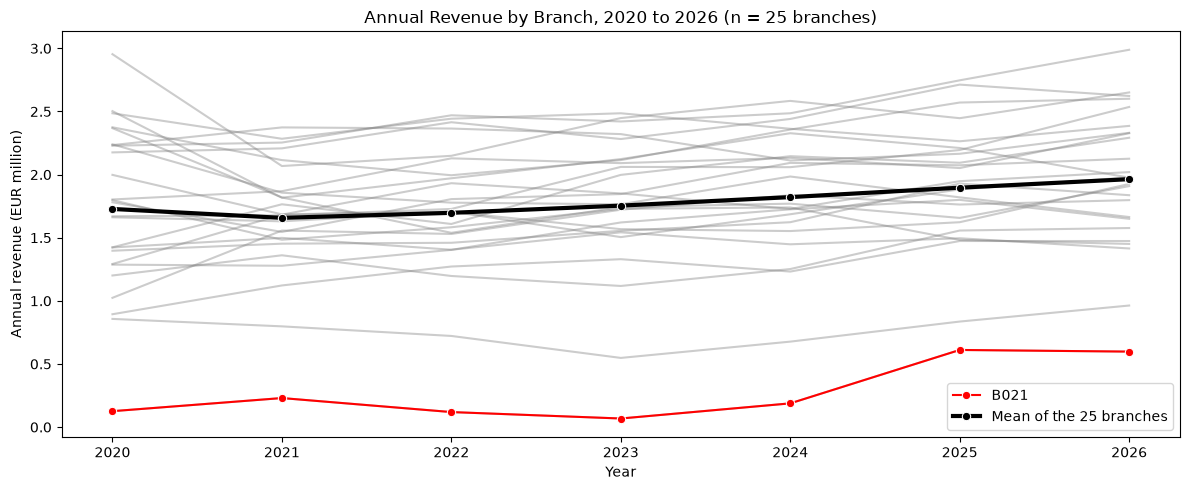

In [15]:
# Revenue of every branch over time, with B021 and the yearly mean highlighted
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(
    data=df,
    x='Year',
    y='Revenue_M_EUR',
    units='Branch_ID',
    estimator=None,
    color='grey',
    alpha=0.4,
    ax=ax,
)
sns.lineplot(
    data=df[df['Branch_ID'] == 'B021'],
    x='Year',
    y='Revenue_M_EUR',
    color='red',
    marker='o',
    label='B021',
    ax=ax,
)
sns.lineplot(
    data=df,
    x='Year',
    y='Revenue_M_EUR',
    errorbar=None,
    color='black',
    linewidth=3,
    marker='o',
    label='Mean of the 25 branches',
    ax=ax,
)
ax.set(
    xlabel='Year',
    ylabel='Annual revenue (EUR million)',
    title=f'Annual Revenue by Branch, 2020 to 2026 (n = {df["Branch_ID"].nunique()} branches)',
)
plt.tight_layout()

In [16]:
# Year-on-year change in each branch's revenue: mean and spread by year
revenue_change = df.groupby('Branch_ID')['Revenue_M_EUR'].diff()
revenue_change.groupby(df['Year']).agg(['mean', 'std', 'min', 'max']).dropna().round(3)

,mean,std,min,max
Year,,,,
2021,-0.071,0.330,-0.886,0.533
2022,0.040,0.150,-0.280,0.260
2023,0.057,0.160,-0.202,0.389
2024,0.068,0.124,-0.209,0.247
2025,0.075,0.181,-0.257,0.423
2026,0.067,0.155,-0.235,0.341


In [17]:
# Branches whose Modern_Type changes over the period
switched = df.groupby('Branch_ID')['Modern_Type'].nunique()
df[df['Branch_ID'].isin(switched[switched > 1].index)].pivot(
    index='Branch_ID', columns='Year', values='Modern_Type'
)

Year,2020,2021,2022,2023,2024,2025,2026
Branch_ID,,,,,,,
B003,0,0,0,0,1,1,1
B025,0,0,0,1,1,1,1


#### Data Preparation
Each issue found above is treated on its own evidence, rather than with one rule for all:

| Issue | Where | Evidence | Treatment | Justification |
|:--|:--|:--|:--|:--|
| Missing `Local_Income_kEUR` | B007, 2023 | 1 of 175 values | Linear interpolation within B007: (44.5 + 46.9) / 2 = 45.7 | Local income moves smoothly. It rises in 77% of yearly steps across all branches, by 0.69 kEUR on average, and B007's rises every year, so its neighbours bracket the gap. The pooled mean (42.2) would place B007 about 3.5 kEUR too low. |
| Missing `Staff_Quality` | B016, 2025 | 1 of 175 values | B016's own median score: 7 | Staff quality is a whole-number score that moves up and down (7, 8, 7, 6, 7, ?, 8). Interpolation would give 7.5, which is not a valid score. B016's median, mode and 2024 value are all 7, so it is chosen here. Dropping the row instead changes no coefficient by more than 0.006 (Question 6 c). |
| `Customer_Rating` of 0.8 | B021, 2026 | Outside the 1-10 scale; B021's other ratings are 5.5 to 5.7 | Set to missing, not imputed | An impossible value, so a recording error. A replacement is not needed: 2026 information has no 2027 outcome to train on, and B021 is not a candidate site, so the model never uses this cell. Any replacement would be guessing. |
| Extreme branch B021 | All years | Competition 10, revenue €0.07 to €0.61 million, lowest footfall and ratings | Kept | Its values are consistent over all 7 years and with each other. It is not an error, and the only branch of very high competition. Removing it changes the slopes by at most 0.003 (Question 6 c). |
| Volatile 2020 revenue | 2020 | 2020 to 2021 change has SD 0.33, against 0.12 to 0.18 later | No action needed | The data does not show why 2020 differs, and it does not need to: 2020 revenue is never an outcome in the next-year design.|
| `Modern_Type` changes | B003 (2024), B025 (2023) | 0 to 1, with revenue rising after | Kept as recorded | A plausible change rather than an error.|
| Repeated revenue | B004, 2025 and 2026 | €1.474 million in both years; the only exact repeat in revenue | Kept | Not a duplicate row, as B004's other variables changed. The final model predicts €1.462 million for B004's 2026 revenue from its 2025 information, only 0.012 away. The value is consistent with the branch and there is no evidence it is wrong. |

In [ ]:
# Local income over time: B007 around its missing year, and the yearly change all branches
print(df[df['Branch_ID'] == 'B007'][['Year', 'Local_Income_kEUR']].T, '\n')
income_change = df.groupby('Branch_ID')['Local_Income_kEUR'].diff()
print(f'Mean yearly change in local income: {income_change.mean():.2f} kEUR')
print(f'Share of yearly changes that are increases: {(income_change > 0).mean():.0%}')
print(f'Pooled mean income: {df["Local_Income_kEUR"].mean():.1f} kEUR')

                       42      43      44      45      46      47      48
Year               2020.0  2021.0  2022.0  2023.0  2024.0  2025.0  2026.0
Local_Income_kEUR    42.1    43.4    44.5     NaN    46.9    48.0    48.5 

Mean yearly change in local income: 0.69 kEUR
Share of yearly changes that are increases: 77%
Pooled mean income: 42.2 kEUR


In [19]:
# Staff quality of B016 in every year, and its median, mode and previous value
b016 = df[df['Branch_ID'] == 'B016'].set_index('Year')['Staff_Quality']
print(b016.to_frame().T, '\n')
print(f'Median: {b016.median()}, mode: {b016.mode().tolist()}, 2024 value: {b016[2024]}')

Year           2020  2021  2022  2023  2024  2025  2026
Staff_Quality   7.0   8.0   7.0   6.0   7.0   NaN   8.0 

Median: 7.0, mode: [7.0], 2024 value: 7.0


In [20]:
# Apply the treatments
df_clean = df.copy()

# 1. Impossible rating: recorded as missing, not imputed
df_clean.loc[~df_clean['Customer_Rating'].between(1, 10), 'Customer_Rating'] = np.nan

# 2. Missing local income: linear interpolation within the branch
df_clean['Local_Income_kEUR'] = df_clean.groupby('Branch_ID')[
    'Local_Income_kEUR'
].transform(lambda s: s.interpolate())

# 3. Missing staff quality: the branch's own median score
df_clean['Staff_Quality'] = df_clean.groupby('Branch_ID')['Staff_Quality'].transform(
    lambda s: s.fillna(s.median())
)

# Show the three treated rows
df_clean.loc[df.isna().any(axis=1) | ~df['Customer_Rating'].between(1, 10)]

,Branch_ID,Year,Revenue_M_EUR,Local_Income_kEUR,Competition,Customer_Rating,Staff_Quality,Modern_Type,Location_Code,Footfall_Monthly
45,B007,2023,2.421,45.7,3,6.8,7.0,1,4,11508
110,B016,2025,1.557,36.1,2,6.6,7.0,0,3,10957
146,B021,2026,0.598,37.8,10,NaN,9.0,0,3,9227


#### Next-Year Design
Each row of the modelling data holds a branch's information in year t and its revenue in year t + 1 (`Revenue_Next`). The 2020 to 2025 inputs predict 2021 to 2026 revenue, giving 6 x 25 = 150 branch-years. The 2026 rows have no 2027 outcome and are not used for fitting.  

Two representation choices are made here:
- `Footfall_k` is monthly footfall in thousands, so its coefficient is per 1,000 customers.
- `Location_Code` becomes four region dummies, explained in b).

In [21]:
# Pair each year's information with the same branch's revenue in the following year
df_clean['Revenue_Next'] = df_clean.groupby('Branch_ID')['Revenue_M_EUR'].shift(-1)
df_model = df_clean.dropna(subset=['Revenue_Next']).copy()

# Footfall in thousands of monthly customers, and one dummy per region with Midlands as the reference
df_model['Footfall_k'] = df_model['Footfall_Monthly'] / 1000
region_dummies = pd.get_dummies(df_model['Location_Code'].map(REGIONS), dtype=int).drop(
    columns='Midlands'
)
df_model = pd.concat([df_model, region_dummies], axis=1)

print(
    'Rows:',
    len(df_model),
    '| Years used as inputs:',
    df_model['Year'].min(),
    'to',
    df_model['Year'].max(),
)
print('Missing values:', df_model.isna().sum().sum())
df_model[df_model['Branch_ID'] == 'B001'][
    ['Branch_ID', 'Year', 'Footfall_k', 'Revenue_M_EUR', 'Revenue_Next']
]

Rows: 150 | Years used as inputs: 2020 to 2025
Missing values: 0


,Branch_ID,Year,Footfall_k,Revenue_M_EUR,Revenue_Next
0,B001,2020,10.890,1.798,1.484
1,B001,2021,10.289,1.484,1.583
2,B001,2022,10.888,1.583,1.729
3,B001,2023,10.782,1.729,1.740
4,B001,2024,10.605,1.740,1.483
5,B001,2025,10.465,1.483,1.451


#### a) Identify the two predictors you initially consider most informative and support your choice with numerical or graphical evidence.
**Chosen predictors: `Footfall_Monthly` (as `Footfall_k`) and `Local_Income_kEUR`.**

Each current-year variable was ranked by its association with next-year revenue, measured four ways (n = 150). Current revenue is the strongest of all in the output below (r = 0.933), but it is not a candidate because a new branch has no revenue.

| Variable (year t) | Pearson r | Spearman rho | r without B021 | Mutual information |
|:--|--:|--:|--:|--:|
| `Footfall_Monthly` | 0.834 | 0.759 | 0.758 | 0.569 |
| `Local_Income_kEUR` | 0.738 | 0.697 | 0.716 | 0.492 |
| `Customer_Rating` | 0.539 | 0.481 | 0.427 | 0.258 |
| `Competition` | -0.440 | -0.302 | -0.210 | 0.323 |
| `Year` | 0.200 | 0.214 | 0.234 | 0.000 |
| `Modern_Type` | 0.114 | 0.113 | 0.025 | 0.012 |
| `Staff_Quality` | 0.056 | 0.147 | 0.217 | 0.000 |

- **Numerical evidence:** footfall and local income are the strongest on every measure. Their lead holds without B021 (r = 0.76 and 0.72; as an extreme branch, B021 can shift a correlation on its own), in Spearman's rank correlation and in mutual information, which also detects nonlinear dependence. So it does not depend on one branch or on a straight-line assumption.
- **Graphical evidence:** the scatterplots below agree. Footfall and income have the clearest positive, roughly straight-line relationships with next-year revenue. Customer rating is more scattered, and competition, staff quality and branch type show little pattern apart from B021 (red).

**Initial model (n = 150):**  
Revenue_Next = -4.6378 + 0.4325 x Footfall_k + 0.0419 x Local_Income_kEUR

Both coefficients are positive and significant (t = 11.27 and 6.05, both p < 0.001), with R2 = 0.756 and adjusted R2 = 0.753. The two predictors overlap (r = 0.66): higher-income areas tend to have busier branches. Income therefore adds less than its own correlation suggests, as footfall alone gives R2 = 0.695, and footfall with customer rating fits slightly better as a pair (adjusted R2 = 0.784). The starting pair is chosen on the individual evidence above, and the remaining variables are tested in c).
  
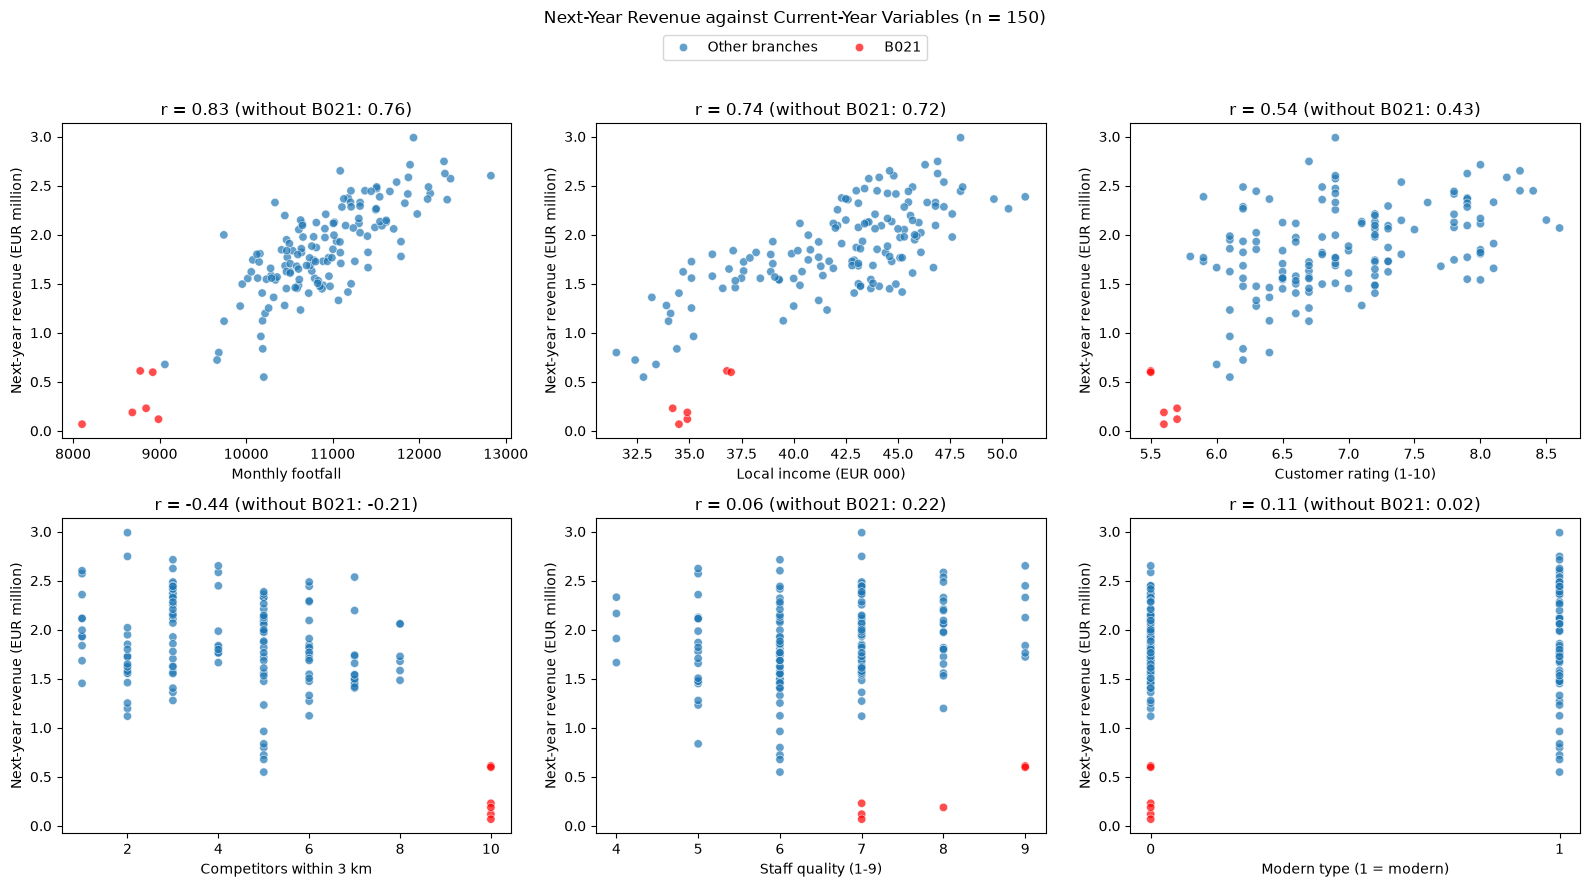

In [22]:
# Association of each current-year variable with next-year revenue
no_b021 = df_model[df_model['Branch_ID'] != 'B021']
variables = [
    'Footfall_Monthly',
    'Local_Income_kEUR',
    'Customer_Rating',
    'Competition',
    'Staff_Quality',
    'Modern_Type',
    'Year',
    'Revenue_M_EUR',
]
mi = mutual_info_regression(df_model[variables], df_model['Revenue_Next'], random_state=0)
assoc = pd.DataFrame(
    {
        'pearson_r': df_model[variables].corrwith(df_model['Revenue_Next']),
        'spearman_rho': df_model[variables].corrwith(
            df_model['Revenue_Next'], method='spearman'
        ),
        'pearson_r_without_B021': no_b021[variables].corrwith(no_b021['Revenue_Next']),
        'mutual_info': mi,
    }
)
assoc.sort_values('pearson_r', key=abs, ascending=False).round(3)

,pearson_r,spearman_rho,pearson_r_without_B021,mutual_info
Revenue_M_EUR,0.933,0.904,0.903,1.030
Footfall_Monthly,0.834,0.759,0.758,0.569
Local_Income_kEUR,0.738,0.697,0.716,0.492
Customer_Rating,0.539,0.481,0.427,0.258
Competition,-0.440,-0.302,-0.210,0.323
Year,0.200,0.214,0.234,0.000
Modern_Type,0.114,0.113,0.025,0.012
Staff_Quality,0.056,0.147,0.217,0.000


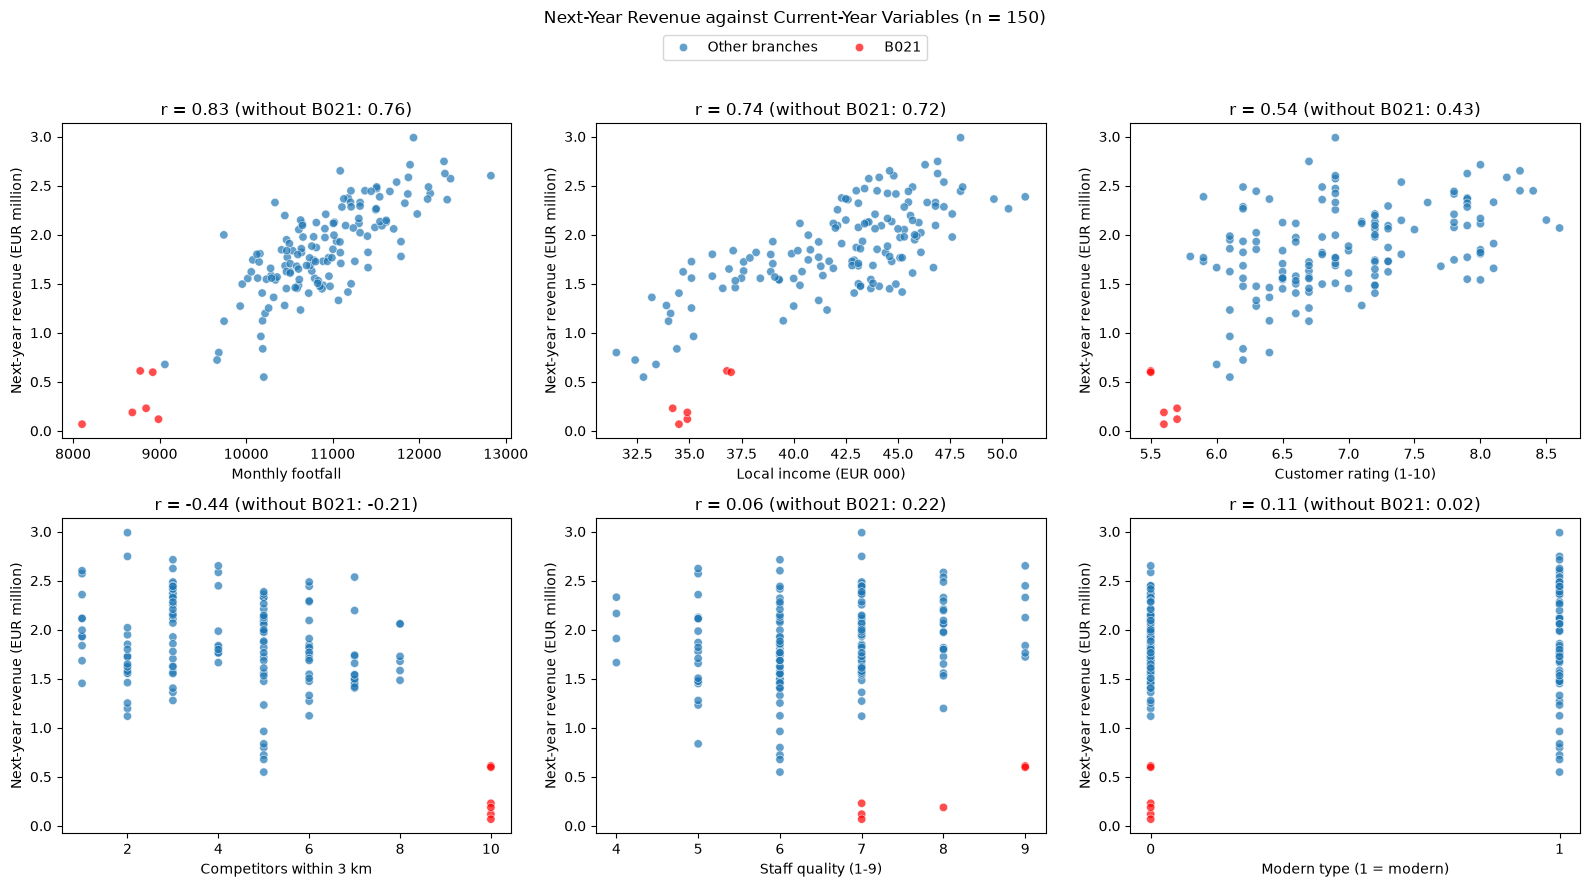

In [23]:
# Next-year revenue against each candidate predictor, with B021 highlighted
labels = {
    'Footfall_Monthly': 'Monthly footfall',
    'Local_Income_kEUR': 'Local income (EUR 000)',
    'Customer_Rating': 'Customer rating (1-10)',
    'Competition': 'Competitors within 3 km',
    'Staff_Quality': 'Staff quality (1-9)',
    'Modern_Type': 'Modern type (1 = modern)',
}
is_b021 = df_model['Branch_ID'].eq('B021').map({True: 'B021', False: 'Other branches'})
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (col, label) in zip(axes.flat, labels.items(), strict=True):
    sns.scatterplot(
        data=df_model,
        x=col,
        y='Revenue_Next',
        hue=is_b021,
        palette={'Other branches': 'tab:blue', 'B021': 'red'},
        alpha=0.7,
        ax=ax,
    )
    ax.set(
        xlabel=label,
        ylabel='Next-year revenue (EUR million)',
        title=f'r = {assoc.loc[col, "pearson_r"]:.2f} (without B021: {assoc.loc[col, "pearson_r_without_B021"]:.2f})',
    )
    ax.get_legend().remove()
axes.flat[-1].set_xticks([0, 1])
handles, legend_labels = axes.flat[0].get_legend_handles_labels()
fig.suptitle(f'Next-Year Revenue against Current-Year Variables (n = {len(df_model)})')
fig.legend(handles, legend_labels, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 0.96))
plt.tight_layout(rect=[0, 0, 1, 0.93])

In [24]:
# Initial model with the two chosen predictors
m1 = smf.ols('Revenue_Next ~ Footfall_k + Local_Income_kEUR', data=df_model).fit()
footfall_only = smf.ols('Revenue_Next ~ Footfall_k', data=df_model).fit()
footfall_rating = smf.ols(
    'Revenue_Next ~ Footfall_k + Customer_Rating', data=df_model
).fit()
print(
    f'Footfall + income: R2 = {m1.rsquared:.3f}, adjusted R2 = {m1.rsquared_adj:.3f}, n = {int(m1.nobs)}'
)
print(f'Footfall alone: R2 = {footfall_only.rsquared:.3f}')
print(f'Footfall + rating: adjusted R2 = {footfall_rating.rsquared_adj:.3f}')
print(
    f'r(footfall, local income) = {df_model["Footfall_k"].corr(df_model["Local_Income_kEUR"]):.2f}'
)
m1.summary().tables[1]

Footfall + income: R2 = 0.756, adjusted R2 = 0.753, n = 150
Footfall alone: R2 = 0.695
Footfall + rating: adjusted R2 = 0.784
r(footfall, local income) = 0.66


,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-4.6378,0.312,-14.883,0.000,-5.254,-4.022
Footfall_k,0.4325,0.038,11.267,0.000,0.357,0.508
Local_Income_kEUR,0.0419,0.007,6.054,0.000,0.028,0.056


#### b) Explain how categorical variables were treated or excluded in your regression analysis and why.

| Variable | Type | Treatment | Reason |
|:--|:--|:--|:--|
| `Location_Code` | Nominal: 5 regions | One-hot encoded, with Midlands (code 1) dropped as the reference: four 0/1 dummies, `North`, `East`, `South` and `West` | The codes 1-5 are labels. As a number, one slope would impose an artificial order and equal steps from Midlands to North to East to South to West. With an intercept, k - 1 = 4 dummies are needed; a fifth would duplicate the intercept (the dummy variable trap).|
| `Modern_Type` | Binary: 0/1 | Used as it is | Already a dummy variable, so its coefficient is the difference between modern and conventional branches. |
| `Branch_ID` | Identifier | Excluded as a predictor; used only to group rows by branch | It names a branch rather than describing it. It has no predictive significance.
| `Year` | Time index | Used to pair year t with t + 1, then excluded as a predictor | A linear trend (p = 0.997) and year dummies (p = 0.999) add nothing in c), and year dummies cannot predict a year not in the data, such as 2027. |
| `Customer_Rating`, `Staff_Quality` | Rating scales: a yearly average (1-10) and a whole-number score (1-9) | Treated as numeric | They have many levels with roughly equal steps. Squared terms, which would capture unequal steps, add nothing in c), so one effect per point is reasonable. |

**Evidence for the region treatment** (output below). As a number, `Location_Code` has r = -0.074 with next-year revenue, which suggests region does not matter. The region means show the opposite, ranging from €1.333 million in the East (€1.591 million without B021) to €2.123 million in the South. With the other site variables held constant, the four dummies are also jointly significant (partial F-test: F(4, 139) = 17.03, p < 0.001) and lower the leave-one-branch-out error from 0.144 to 0.111 (c), so region is kept rather than excluded.

In [ ]:
# Next-year revenue by region, and the misleading correlation with the numeric code
region_means = (
    df_model.groupby('Location_Code')['Revenue_Next']
    .mean()
    .rename(index=REGIONS)
    .to_frame('mean next-year revenue')
)
print(region_means.round(3), '\n')
print(f"Pearson r of Location_Code (as a number) with next-year revenue: {df_model['Location_Code'].corr(df_model['Revenue_Next']):.3f}")
east_without_b021 = no_b021.loc[no_b021['Location_Code'] == 3, 'Revenue_Next'].mean()
print(f'East mean without B021: {east_without_b021:.3f}')

               mean next-year revenue
Location_Code                        
Midlands                        1.906
North                           1.951
East                            1.333
South                           2.123
West                            1.679 

Pearson r of Location_Code (as a number) with next-year revenue: -0.074
East mean without B021: 1.591


In [25]:
# Next-year revenue by region, and the misleading correlation with the numeric code
region_stats = (
    df_model.groupby('Location_Code')['Revenue_Next']
    .agg(['mean', 'count'])
    .rename(index=REGIONS)
)
region_stats['branches'] = (
    df_model.groupby('Location_Code')['Branch_ID'].nunique().to_numpy()
)
print(region_stats.round(3), '\n')
print(
    f'Pearson r of Location_Code (as a number) with next-year revenue: {df_model["Location_Code"].corr(df_model["Revenue_Next"]):.3f}'
)
east_without_b021 = no_b021.loc[no_b021['Location_Code'] == 3, 'Revenue_Next'].mean()
print(f'East mean without B021: {east_without_b021:.3f}')

                mean  count  branches
Location_Code                        
Midlands       1.906     30         5
North          1.951     30         5
East           1.333     30         5
South          2.123     30         5
West           1.679     30         5 

Pearson r of Location_Code (as a number) with next-year revenue: -0.074
East mean without B021: 1.591


#### c) Report your final regression model, justify its selection and interpret the most important coefficients in context.


##### Final Model
**M3 (n = 150, R2 = 0.961, adjusted R2 = 0.958, residual SE = €0.110 million):**  

`Revenue_Next` is the following year's revenue in € million, and every predictor is a current-year value: `Footfall_k` is monthly footfall / 1,000, income is in €000, and Midlands is the reference region.

| Term | Coefficient | SE | t | 95% CI | p-value |
|:--|--:|--:|--:|:--|--:|
| Intercept | -4.6942 | 0.1962 | -23.93 | -5.0821 to -4.3063 | < 0.001 |
| `Footfall_k` | 0.1370 | 0.0226 | 6.07 | 0.0924 to 0.1816 | < 0.001 |
| `Local_Income_kEUR` | 0.0670 | 0.0034 | 19.83 | 0.0603 to 0.0737 | < 0.001 |
| `Customer_Rating` | 0.2705 | 0.0170 | 15.87 | 0.2368 to 0.3043 | < 0.001 |
| `Competition` | -0.0847 | 0.0057 | -14.79 | -0.0960 to -0.0734 | < 0.001 |
| `Staff_Quality` | 0.1076 | 0.0087 | 12.39 | 0.0904 to 0.1248 | < 0.001 |
| `Modern_Type` | 0.1557 | 0.0249 | 6.26 | 0.1066 to 0.2049 | < 0.001 |
| `North` | -0.1052 | 0.0342 | -3.08 | -0.1727 to -0.0376 | 0.003 |
| `East` | -0.0673 | 0.0338 | -1.99 | -0.1340 to -0.0005 | 0.048 |
| `South` | 0.0481 | 0.0298 | 1.61 | -0.0109 to 0.1071 | 0.109 |
| `West` | -0.1749 | 0.0303 | -5.78 | -0.2347 to -0.1151 | < 0.001 |

Each p-value is from a t-test of H0: coefficient = 0 against H1: coefficient not equal to 0, with 139 degrees of freedom. The slopes are stable: none changes by more than 0.003 without B021 or without the imputed B016 row.

##### Justification of the Selection
**M3 is best at predicting branches it has not seen.** It has the lowest leave-one-branch-out error (0.111) and the highest adjusted R2 (0.958) of the candidates below, every extension of it makes that error worse, and it uses only information a new branch would have in 2026.

R2 can only rise as predictors are added, so the candidates, all fitted to the same 150 branch-years, are also compared on adjusted R2 and two out-of-sample errors:
- **Leave-one-branch-out (LOBO) RMSE:** each branch in turn is left out, and the model fitted to the other 24 predicts its six next-year revenues. This imitates the real task, predicting a branch the model has never seen.
- **Holdout RMSE:** the model is fitted to the 2020-2024 inputs and predicts 2026 revenue from 2025 inputs, a one-year-ahead forecast.

| Model | Predictors | R2 | Adjusted R2 | Residual SE | LOBO RMSE | Holdout RMSE |
|:--|--:|--:|--:|--:|--:|--:|
| M1: footfall + income | 2 | 0.756 | 0.753 | 0.267 | 0.287 | 0.312 |
| M2: + rating, competition, staff quality, modern type | 6 | 0.942 | 0.940 | 0.132 | 0.144 | 0.138 |
| **M3: + region dummies (final)** | **10** | **0.961** | **0.958** | **0.110** | **0.111** | **0.115** |
| M3 + linear year trend | 11 | 0.961 | 0.958 | 0.110 | 0.113 | 0.115 |
| M3 + squared terms | 15 | 0.962 | 0.958 | 0.110 | 0.123 | 0.115 |
| M3 + interactions | 12 | 0.961 | 0.958 | 0.110 | 0.121 | 0.116 |
| M3 + current revenue (lag) | 11 | 0.961 | 0.958 | 0.110 | 0.113 | 0.114 |

The brief suggests three ways to improve on M1:
- **Other relevant variables:** the largest gain. Adding rating, competition, staff quality and modern type halves the LOBO error (0.287 to 0.144), and region dummies cut it to 0.111 (partial F-test: F(4, 139) = 17.03, p < 0.001).
- **Temporal structure:** the next-year pairing builds time into every row, as each input is a year older than its outcome. A linear trend adds nothing (p = 0.997) because rising local income already carries it: without income, the trend is significant (p = 0.007). Year dummies (F(5, 134) = 0.04, p = 0.999) and current revenue as a lag (p = 0.520) add nothing either, and a new branch has no revenue to lag. Each branch appears in six years, so its rows may not be independent; d) finds almost no correlation left within a branch.
- **Feature engineering:** squared terms and interactions (footfall x income, footfall x competition) barely change R2 but worsen the LOBO error (0.123 and 0.121), a sign of overfitting. A log of revenue was not used: revenue is left-skewed, which a log would worsen, and the residuals are already close to normal with constant variance (d).

**Each variable earns its place:** removing any one of them from M3 raises the LOBO error above 0.111.

| Removed from M3 | LOBO RMSE |
|:--|--:|
| Local income | 0.248 |
| Customer rating | 0.232 |
| Competition | 0.214 |
| Staff quality | 0.190 |
| Region dummies | 0.144 |
| Modern type | 0.136 |
| Footfall | 0.127 |

The holdout does not separate the M3 variants, which are all within 0.002 of each other (0.114 to 0.116), so the simplest, M3, is kept.

##### Interpretation of the Most Important Coefficients
**Local income, customer rating and competition matter most.** A typical difference in each, one standard deviation (SD), moves next-year revenue by €0.185 to €0.284 million, about 10% to 16% of the average branch's €1.80 million.

Each coefficient is the difference in next-year revenue associated with a one-unit difference in that predictor this year, holding the other predictors constant. Almost every p-value is below 0.001, so significance does not separate the predictors. Their units also differ, so importance is compared through the effect of a 1 SD difference:

| Predictor | Coefficient | Effect of 1 SD (€ million) | Marginal r | Partial r |
|:--|:--|--:|--:|--:|
| Local income | +0.067 per €1,000 | 0.284 | 0.738 | 0.860 |
| Customer rating | +0.271 per point | 0.192 | 0.539 | 0.803 |
| Competition | -0.085 per competitor | -0.185 | -0.440 | -0.782 |
| Staff quality | +0.108 per point | 0.123 | 0.056 | 0.724 |
| Footfall | +0.137 per 1,000 customers | 0.105 | 0.834 | 0.458 |

- **Local income (most important):** €1,000 more average local income goes with €67,000 more revenue the following year, and a typical difference between areas (SD €4,235) with €284,000.
- **Customer rating:** each extra point goes with €271,000 more, and a typical difference of 0.7 points with €192,000.
- **Competition:** each extra competitor within 3 km goes with €85,000 less. This is not only B021: without it the coefficient is still -0.083.
- **Staff quality:** each extra point goes with €108,000 more. On its own it looked irrelevant (r = 0.056), but with the other predictors held constant its partial r is 0.724. Higher staff quality tends to come with more competition (r = 0.14) and lower footfall (r = -0.14), most of all in B021 (staff quality 7 to 9, very low revenue), which hides its effect.
- **Footfall:** 1,000 more monthly customers go with €137,000 more, far less than 0.4325 in M1, where footfall also stood in for the income, rating and competition it is correlated with (multicollinearity). It is the strongest single predictor but the smallest unique contributor of the five.
- **Modern type and region:** modern branches earn €156,000 more than comparable conventional ones. Compared with Midlands, the West earns €175,000 less and the North €105,000 less; the East is €67,000 less, only just significant (p = 0.048), and the South is not significantly different (p = 0.109).
- **Intercept:** the prediction when every predictor is 0 (no customers, no local income, a rating of 0), far outside the data, so it has no practical meaning.

These are associations in observational data, not causal effects. A higher rating, for example, may partly reflect a better location rather than cause higher revenue.

In [ ]:
# Final model (M3): coefficients with 95% confidence intervals
base = 'Footfall_k + Local_Income_kEUR'
others = ' + Customer_Rating + Competition + Staff_Quality + Modern_Type'
region = ' + North + East + South + West'
final = smf.ols(f'Revenue_Next ~ {base}{others}{region}', data=df_model).fit()
final.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-4.6942,0.196,-23.927,0.000,-5.082,-4.306
Footfall_k,0.1370,0.023,6.074,0.000,0.092,0.182
Local_Income_kEUR,0.0670,0.003,19.833,0.000,0.060,0.074
Customer_Rating,0.2705,0.017,15.869,0.000,0.237,0.304
Competition,-0.0847,0.006,-14.786,0.000,-0.096,-0.073
Staff_Quality,0.1076,0.009,12.390,0.000,0.090,0.125
Modern_Type,0.1557,0.025,6.260,0.000,0.107,0.205
North,-0.1052,0.034,-3.079,0.003,-0.173,-0.038
East,-0.0673,0.034,-1.991,0.048,-0.134,-0.000
South,0.0481,0.030,1.612,0.109,-0.011,0.107


In [ ]:
# Sensitivity of the coefficients to B021 and to the staff-quality imputation
no_b021_fit = smf.ols(final.model.formula, data=df_model[df_model['Branch_ID'] != 'B021']).fit()
no_imputed_fit = smf.ols(
    final.model.formula,
    data=df_model[~((df_model['Branch_ID'] == 'B016') & (df_model['Year'] == 2025))],
).fit()
b021_resid = final.resid[df_model['Branch_ID'] == 'B021']
print(f'B021 residuals in the final model: {b021_resid.min():.3f} to {b021_resid.max():.3f}')
b004_2026 = (df_model['Branch_ID'] == 'B004') & (df_model['Year'] == 2025)
print(
    f'B004 2026 revenue: actual {df_model.loc[b004_2026, "Revenue_Next"].iloc[0]:.3f}, '
    f'predicted {final.fittedvalues[b004_2026].iloc[0]:.3f}, residual {final.resid[b004_2026].iloc[0]:.3f}'
)
pd.DataFrame(
    {'final': final.params, 'without B021': no_b021_fit.params, 'without imputed B016 row': no_imputed_fit.params}
).round(4)

B021 residuals in the final model: -0.137 to 0.095
B004 2026 revenue: actual 1.474, predicted 1.462, residual 0.012


,final,without B021,without imputed B016 row
Intercept,-4.6942,-4.6646,-4.6885
Footfall_k,0.1370,0.1375,0.1357
Local_Income_kEUR,0.0670,0.0665,0.0672
Customer_Rating,0.2705,0.2685,0.2704
Competition,-0.0847,-0.0834,-0.0845
Staff_Quality,0.1076,0.1067,0.1074
Modern_Type,0.1557,0.1531,0.1563
North,-0.1052,-0.1050,-0.1064
East,-0.0673,-0.0668,-0.0704
South,0.0481,0.0486,0.0472


In [ ]:
# Candidate models, each fitted to the same 150 branch-years
candidates = {
    'M1: two predictors': base,
    'M2: + other site variables': base + others,
    'M3: + region dummies': base + others + region,
    'M3 + linear year trend': base + others + region + ' + Year',
    'M3 + squared terms': base + others + region
    + ' + I(Footfall_k**2) + I(Local_Income_kEUR**2) + I(Competition**2) + I(Customer_Rating**2) + I(Staff_Quality**2)',
    'M3 + interactions': base + others + region + ' + Footfall_k:Local_Income_kEUR + Footfall_k:Competition',
    'M3 + current revenue (lag)': base + others + region + ' + Revenue_M_EUR',
}
fits = {name: smf.ols(f'Revenue_Next ~ {terms}', data=df_model).fit() for name, terms in candidates.items()}
comparison = pd.DataFrame({name: fit_stats(fit, df_model) for name, fit in fits.items()}).T
comparison.round(4)

,n,predictors,R2,adj_R2,resid_SE,LOBO_RMSE,holdout_RMSE
M1: two predictors,150.0,2.0,0.7558,0.7525,0.2674,0.2869,0.3122
M2: + other site variables,150.0,6.0,0.9421,0.9397,0.1320,0.1439,0.1378
M3: + region dummies,150.0,10.0,0.9612,0.9584,0.1096,0.1112,0.1149
M3 + linear year trend,150.0,11.0,0.9612,0.9581,0.1100,0.1125,0.1151
M3 + squared terms,150.0,15.0,0.9622,0.9579,0.1102,0.1226,0.1147
M3 + interactions,150.0,12.0,0.9612,0.9578,0.1104,0.1214,0.1158
M3 + current revenue (lag),150.0,11.0,0.9613,0.9582,0.1099,0.1126,0.1144


In [ ]:
# Tests behind the choices
m2, m3 = fits['M2: + other site variables'], fits['M3: + region dummies']
f_region, p_region, df_region = m3.compare_f_test(m2)
print(f'Region dummies, partial F-test: F({int(df_region)}, {int(m3.df_resid)}) = {f_region:.2f}, p = {p_region:.2g}')
trend = fits['M3 + linear year trend']
print(f"Year trend: coefficient = {trend.params['Year']:.4f}, p = {trend.pvalues['Year']:.3f}")
no_income = smf.ols(f'Revenue_Next ~ Footfall_k{others}{region} + Year', data=df_model).fit()
print(f"Year trend without local income: coefficient = {no_income.params['Year']:.4f}, p = {no_income.pvalues['Year']:.3f}")
lagged = fits['M3 + current revenue (lag)']
print(f"Current revenue: coefficient = {lagged.params['Revenue_M_EUR']:.3f}, p = {lagged.pvalues['Revenue_M_EUR']:.3f}")
year_dummies = smf.ols(f"Revenue_Next ~ {candidates['M3: + region dummies']} + C(Year)", data=df_model).fit()
f_year, p_year, df_year = year_dummies.compare_f_test(m3)
print(f'Year dummies, partial F-test: F({int(df_year)}, {int(year_dummies.df_resid)}) = {f_year:.2f}, p = {p_year:.3f}')

Region dummies, partial F-test: F(4, 139) = 17.03, p = 2.2e-11
Year trend: coefficient = -0.0000, p = 0.997
Year trend without local income: coefficient = 0.0278, p = 0.007
Current revenue: coefficient = -0.037, p = 0.520
Year dummies, partial F-test: F(5, 134) = 0.04, p = 0.999


In [ ]:
# Leave-one-branch-out error when each variable is removed from M3 on its own
m3_terms = candidates['M3: + region dummies'].split(' + ')
removals = {
    'Local income': ['Local_Income_kEUR'],
    'Customer rating': ['Customer_Rating'],
    'Competition': ['Competition'],
    'Staff quality': ['Staff_Quality'],
    'Region dummies': ['North', 'East', 'South', 'West'],
    'Modern type': ['Modern_Type'],
    'Footfall': ['Footfall_k'],
}
drop_one = {
    name: lobo_rmse('Revenue_Next ~ ' + ' + '.join(t for t in m3_terms if t not in removed), df_model)
    for name, removed in removals.items()
}
pd.Series(drop_one, name='LOBO RMSE without it').round(3)

Local income       0.248
Customer rating    0.232
Competition        0.214
Staff quality      0.190
Region dummies     0.144
Modern type        0.136
Footfall           0.127
Name: LOBO RMSE without it, dtype: float64

In [ ]:
# Size of each effect: change in next-year revenue for a one standard deviation change,
# and the correlation before (marginal) and after (partial) holding the other predictors constant
numeric = ['Local_Income_kEUR', 'Customer_Rating', 'Competition', 'Staff_Quality', 'Footfall_k']
terms = final.model.exog_names[1:]
importance = {}
for col in numeric:
    rest = ' + '.join(t for t in terms if t != col)
    resid_y = smf.ols(f'Revenue_Next ~ {rest}', data=df_model).fit().resid
    resid_x = smf.ols(f'{col} ~ {rest}', data=df_model).fit().resid
    importance[col] = {
        'coefficient': final.params[col],
        'SD of predictor': df_model[col].std(),
        'effect of 1 SD': final.params[col] * df_model[col].std(),
        'marginal r': df_model[col].corr(df_model['Revenue_Next']),
        'partial r': np.corrcoef(resid_y, resid_x)[0, 1],
    }
staff_r = df_model[['Competition', 'Footfall_k']].corrwith(df_model['Staff_Quality'])
print(f"Staff quality: r with competition = {staff_r['Competition']:.2f}, r with footfall = {staff_r['Footfall_k']:.2f}")
print(f"Mean revenue: {df_model['Revenue_Next'].mean():.3f}")
pd.DataFrame(importance).T.round(3)

Staff quality: r with competition = 0.14, r with footfall = -0.14
Mean revenue: 1.799


,coefficient,SD of predictor,effect of 1 SD,marginal r,partial r
Local_Income_kEUR,0.067,4.235,0.284,0.738,0.860
Customer_Rating,0.271,0.711,0.192,0.539,0.803
Competition,-0.085,2.185,-0.185,-0.440,-0.782
Staff_Quality,0.108,1.142,0.123,0.056,0.724
Footfall_k,0.137,0.763,0.105,0.834,0.458
